In [84]:
import os
import glob
import numpy as np
import skimage.io, skimage.morphology
import matplotlib.pyplot as plt

import csv
from multiprocessing import Manager, Lock
from concurrent.futures import ProcessPoolExecutor, as_completed

In [2]:
class Plate:

    def __init__(self, _name):
        self.name = _name
    
    def set_file_lists(self, _file_lists):
        self.fch1 = _file_lists[0]
        self.fch2 = _file_lists[1]
        self.fch3 = _file_lists[2]
        self.fch4 = _file_lists[3]

        assert(len(self.fch1) == len(self.fch2))
        assert(len(self.fch1) == len(self.fch3))
        assert(len(self.fch1) == len(self.fch4))
        self.num_images = len(self.fch1)
        

In [72]:
# Find all image pairs

BASE_DIR = "/media/user/SSD2/Athena/Hao_PRPC/PRPC/2025-07-09_60x_3plates/20250613 Lzso50screen/60x"
NUM_PLATES = 3

plates = []  # holds `plate` objects

for i in range(NUM_PLATES):

    plate_name = "plate%d" % (i+1)
    plate = Plate(plate_name)

    ch1_list = sorted(glob.glob("%s/%s_IJsplit/CH1/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch2_list = sorted(glob.glob("%s/%s_IJsplit/CH2/probabilities_cells/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch3_list = sorted(glob.glob("%s/%s_IJsplit/CH3/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch4_list = sorted(glob.glob("%s/%s_IJsplit/CH4/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))

    plate.set_file_lists([ch1_list, ch2_list, ch3_list, ch4_list])

    plates.append(plate)
    

In [87]:
def pmap_to_mask(x):
    mask = np.zeros(x.shape, dtype=np.int32)
    mask[x>0.5] = 1
    return mask

def remove_small_homes(mask, area_threshold=400):
    mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold)
    return mask.astype(np.int32)

def compute_rdf(Nbins):

    # distance to nearest nucleus
    cellArea = np.sum(cell_labels>0)
    dist_nuc = distance_to_nucleus_of_specific_cell(img_nuc, cell_labels)

    # keep distance transform only inside cells
    dist_nuc[mask_cel==0] = 0

    # rdf of lysosomes in cells
    rdf, Nbins, dx = get_rdf(mask_lys, dist_nuc) 




In [90]:
def process_image_pair(paths, debug=False):

    for p in paths:
        print(os.path.basename(p))

    fnuc = paths[0]
    fcel = paths[1]
    flys = paths[2]
    fprp = paths[3]

    # load image files
    img_nuc = skimage.io.imread(fnuc, plugin='tifffile').astype(float)  # probability map from ilastik
    img_cel = skimage.io.imread(fcel, plugin='tifffile').astype(float)  # probability map from ilastik
    img_lys = skimage.io.imread(flys, plugin='tifffile').astype(float)  # probability map from ilastik
    img_prp = skimage.io.imread(fprp, plugin='tifffile').astype(float)  # probability map from ilastik

    # convert probability map to mask
    mask_nuc = pmap_to_mask(img_nuc)
    mask_cel = pmap_to_mask(img_cel)
    mask_lys = pmap_to_mask(img_lys)
    mask_prp = pmap_to_mask(img_prp)

    # remove small holes from nuclei and cells
    mask_nuc = remove_small_homes(mask_nuc, area_threshold=400)
    mask_cel = remove_small_homes(mask_cel, area_threshold=11000)

    # remove small disconnected artifacts in nucleus and cell channels
    mask_nuc = skimage.morphology.remove_small_objects(ar=mask_nuc>0, min_size=1000, connectivity=2).astype(np.int32) # If ar is bool, the image is first labeled
    mask_cel = skimage.morphology.remove_small_objects(ar=mask_cel>0, min_size=5000, connectivity=2).astype(np.int32)
    if debug:
        print("dtypes after remove_small_objects:")
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print("")

    # remove signal outside cells
    mask_nuc[mask_cel==0] = 0
    mask_lys[mask_cel==0] = 0
    mask_prp[mask_cel==0] = 0

    if debug:
        fig = plt.figure(figsize=(20,20))
        plt.subplot(1,4,1)
        plt.imshow(mask_nuc)
        plt.subplot(1,4,2)
        plt.imshow(mask_cel)
        plt.subplot(1,4,3)
        plt.imshow(mask_lys)
        plt.subplot(1,4,4)
        plt.imshow(mask_prp)
        plt.show()
    
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print(mask_lys.dtype)
        print(mask_prp.dtype)

    # Compute total area per structure
    area_nuc = np.sum(mask_nuc)
    area_cel = np.sum(mask_cel)
    area_lys = np.sum(mask_lys)
    area_prp = np.sum(mask_prp)

    if debug:
        well, field = paths[0].split("POM2_")[1].split("_")[0].split("-")
        print("well", well)
        print("field", field)
        print("area_nuc", area_nuc, area_nuc==np.sum(mask_nuc>0), float(area_nuc)/(mask_nuc.shape[0]*mask_nuc.shape[1]))
        print("area_cel", area_cel, area_cel==np.sum(mask_cel>0), float(area_cel)/(mask_cel.shape[0]*mask_cel.shape[1]))
        print("area_lys", area_lys, area_lys==np.sum(mask_lys>0), float(area_lys)/(mask_lys.shape[0]*mask_lys.shape[1]))
        print("area_prp", area_prp, area_prp==np.sum(mask_prp>0), float(area_prp)/(mask_prp.shape[0]*mask_prp.shape[1]))



    # Compute rdf of lysosomes from nearest nucleus
    NBINS = 150
    if area_nuc>0 and area_lys>0:
        compute_rdf(NBINS)
    else:
        rdf = np.zeros(NBINS)

    return area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf


    

20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH1_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH2_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH3_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH4_Probabilities.tif


/tmp/ipykernel_2112146/2568389030.py:7: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold)


dtypes after remove_small_objects:
bool
bool



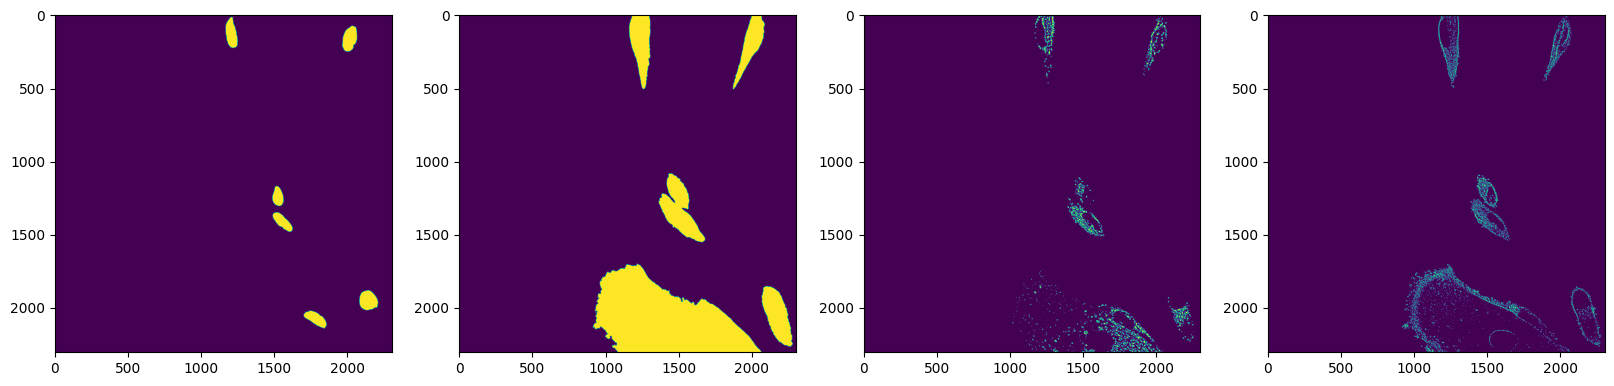

bool
bool
int32
int32
well B10
field 10
area_nuc 66403 True 0.012509004569347993
area_cel 615687 True 0.1159831859447338
area_lys 51404 True 0.009683491271219136
area_prp 56066 True 0.010561719352816358


NameError: name 'cell_labels' is not defined

In [91]:
# Loop over plates and images - SINGLE

for plate in plates:
    for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4):
        area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf = process_image_pair(paths, debug=True)
        
        assert(0)


In [ ]:
def process_images_multi(args, shared_list, lock):

    plate_name = args[0]
    paths = args[1]

    area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf = process_image_pair(paths)

    # get row, column from file name
    well, field = paths[0].split("POM2_")[1].split("_")[0].split("-")
    row = well[0]
    col = int(well[1::])

    result = {
        "Plate": plate_name,
        "File": os.path.basename(paths[4]),
        "Well": well,
        "Row": row,
        "Column": col,
        "AreaNuclei": area_nuc,
        "AreaCells": area_cel,
        "AreaLyso": area_lys,
        "AreaPrPC": area_prp,
        "PrPc_in_DAPI": total_prpc_nucleus,
        "PrPc_in_Cytoplasm": total_prpc_cytoplasm,
        "PrPc_in_CellEdge": total_prpc_celledge,
        "PrPc_in_Lysosome": total_prpc_lysosome,
        "LysosomeRDF": ",".join(map(str,rdf))
    }

    with lock:
        shared_list.append(result)
    

In [ ]:
# Loop over plates and images - MULTI


assert(0)


max_workers = 64

for plate in plates:
    plate_name = plate.name
    print("PROCESSING PLATE:", plate_name)

    Nfiles = plate.num_images

    output_file = "output_2025-08-21_60x_%s.csv" % plate_name

    with Manager() as manager:
        shared_list = manager.list()
        lock = manager.Lock()

        with ProcessPoolExecutor(max_workers=max_workers) as executor:
            futures = [
                executor.submit(process_images, [plate_name, paths], shared_list, lock)
                for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4)
            ]
            for i,future in enumerate(as_completed(futures), 1):
                future.result()
                if i%10==0 or i==Nfiles:
                    print(f"Processed {i}/{Nfiles} images")

        header = ["Plate", "File", "Well", "Row", "Column",
                    "AreaNuclei", "AreaCells", "AreaLyso", "AreaPrPC", 
                    "PrPc_in_DAPI", "PrPc_in_Cytoplasm", "PrPc_in_CellEdge", "PrPc_in_Lysosome",
                    "LysosomeRDF"]

        with open(output_file, 'w', newline='\n') as f:
            writer = csv.DictWriter(f, fieldnames=header)
            writer.writeheader()
            for row in shared_list:
                writer.writerow(row)

In [ ]:
# Export total area per structure (nuclei, cells, lyso, prpc), per image

In [ ]:
# PrPC distribution within cell area

In [ ]:
# Lysosome distance from nearest nucleus